# Explicit & Semiexplicit extended-phase-space integrators

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Could not find the project root containing the src folder.")
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: C:\Users\USER\Desktop\hamiltonian-dynamics-benchmark


In [2]:
import time, warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

from src.datasets.generate import generate_dataset
from src.datasets.systems.low_dim import (
    SimplePendulum,
    DoublePendulum,
    MassSpringSystem,
    HenonHeiles,
)
from src.datasets.systems.high_dim import CoupledOscillators
from src.datasets.integrators import midpoint, verlet
from src.integrators.explicit_extended_space import tao, pihajoki
from src.integrators import INTEGRATORS as EXT


warnings.filterwarnings("ignore")
plt.rcParams.update(
    {"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "legend.fontsize": 8}
)

## Configuration

In [3]:
SYSTEM_BUILDERS = {
    "simple_pendulum": lambda: SimplePendulum(),
    "double_pendulum": lambda: DoublePendulum(),
    "mass_spring": lambda: MassSpringSystem(),
    "henon_heiles": lambda: HenonHeiles(),
    "coupled_oscillators": lambda: CoupledOscillators(n=3),
}
SYSTEM = "simple_pendulum"
N_TEST, SEED_TEST = 3, 123  # number of test trajectories

# True dynamics
A_T, A_STEPS = 50.0, 1000  # long run for the energy-drift plot
CONV_T, CONV_STEPS = 10.0, [
    50,
    100,
    200,
    400,
]  

# Learned models
MODELS = ["MLP", "HNN", "DoubleHeadHNN", "CholeskyHNN", "GeoHNN"]
N_TRAIN, TSPAN_TRAIN, STEPS_TRAIN, SEED_TRAIN = 30, (0.0, 10.0), 500, 42
HIDDEN, EPOCHS, BATCH, LR = 64, 40, 256, 1e-3
ROLL_T, ROLL_STEPS = 15.0, 300
FOCUS_MODEL = "GeoHNN"
OMEGAS = [0.0, 1.0, 10.0, 100.0]  # Tao restraint sweep
REF_RTOL, REF_ATOL = 1e-6, 1e-8  # tight reference solve of the learned field

# Methods: label -> (solver name, omega)
CANDIDATES = {
    "Tao (ω=10)": ("tao", 10.0),
    "Pihajoki": ("pihajoki", None),
    "J-O (order 2)": ("jayawardana_ohsawa", None),
    "J-O (order 4)": ("jayawardana_ohsawa4", None),
}
BASELINES = {
    "Midpoint": ("midpoint", None),
    "RK4": ("rk4", None),
}
VERLET = {"Verlet": ("verlet", None)}  # separable only

METHODS_TRUE = {**CANDIDATES, **BASELINES, **VERLET}
METHODS_LEARNED = {k: v for k, v in METHODS_TRUE.items() if k not in ("Verlet")}

COLORS = {
    "Tao (ω=10)": "tab:blue",
    "Pihajoki": "tab:orange",
    "Midpoint": "tab:green",
    "RK4": "tab:red",
    "Verlet": "tab:purple",
    "J-O (order 2)": "tab:cyan", 
    "J-O (order 4)": "tab:brown",
}


def sty(label):
    return dict(
        color=COLORS.get(label),
        ls="--" if label in BASELINES or label in VERLET else "-",
        lw=1.5,
    )

## Helpers

In [4]:
def stack(Y, d):
    # (N, 2d) -> flat [q_all, p_all]
    Y = np.asarray(Y, float)
    return np.concatenate([Y[:, :d].ravel(), Y[:, d:].ravel()])


def unstack(flat_traj, N, d):
    # (T, 2Nd) -> (N, T, 2d)
    q = flat_traj[:, : N * d].reshape(-1, N, d)
    p = flat_traj[:, N * d :].reshape(-1, N, d)
    return np.concatenate([q, p], axis=2).transpose(1, 0, 2)


def oracle_field_batched(system, N, d):
    # true dynamics for N trajectories stacked as one big system
    def f(t, flat):
        q = flat[: N * d].reshape(N, d)
        p = flat[N * d :].reshape(N, d)
        out = np.empty((N, 2 * d))
        for i in range(N):
            out[i] = system.dynamics(t, np.concatenate([q[i], p[i]]))
        return np.concatenate([out[:, :d].ravel(), out[:, d:].ravel()])

    return f


def solve_reference(f_flat, Y0, d, T, n, rtol, atol):
    # tight DOP853 solve on the same time grid -> (N, n+1, 2d)
    sol = solve_ivp(
        f_flat,
        (0.0, T),
        stack(Y0, d),
        method="DOP853",
        t_eval=np.linspace(0.0, T, n + 1),
        rtol=rtol,
        atol=atol,
    )
    if not sol.success:
        raise RuntimeError(sol.message)
    return unstack(sol.y.T, len(Y0), d)


class Counted:
    # counts field evaluations (weight = number of trajectories one call evaluates)
    def __init__(self, f, weight=1):
        self.f, self.w, self.n = f, weight, 0

    def __call__(self, t, y):
        self.n += self.w
        return self.f(t, y)


def rk4(f, tspan, y0, n):
    h = (tspan[1] - tspan[0]) / n
    y = np.asarray(y0, float).copy()
    t = tspan[0]
    out = np.empty((n + 1, y.size))
    out[0] = y
    for i in range(n):
        k1 = f(t, y)
        k2 = f(t + h / 2, y + h / 2 * k1)
        k3 = f(t + h / 2, y + h / 2 * k2)
        k4 = f(t + h, y + h * k3)
        y = y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        t += h
        out[i + 1] = y
    return tspan[0] + h * np.arange(n + 1), out


SINGLE = {"midpoint": midpoint, "verlet": verlet}  # run one trajectory at a time
BATCHED = {"rk4": rk4, "pihajoki": pihajoki,
           "jayawardana_ohsawa": EXT["jayawardana_ohsawa"],
           "jayawardana_ohsawa4": EXT["jayawardana_ohsawa4"]}


def run_method(name, omega, Y0, d, T, n, f_flat, f_single):
    # -> dict(traj=(N, n+1, 2d), seconds, evals = field evaluations per trajectory-step)
    N = len(Y0)
    t0 = time.perf_counter()
    try:
        if name in SINGLE:
            cs = Counted(f_single)
            traj = np.stack(
                [SINGLE[name](cs, (0.0, T), np.asarray(y0, float), n)[1] for y0 in Y0]
            )
            evals = cs.n
        else:
            cf = Counted(f_flat, weight=N)
            flat0 = stack(Y0, d)
            if name == "tao":
                _, y = tao(cf, (0.0, T), flat0, n, omega=omega)
            else:
                _, y = BATCHED[name](cf, (0.0, T), flat0, n)
            traj, evals = unstack(y, N, d), cf.n
        return dict(traj=traj, seconds=time.perf_counter() - t0, evals=evals / (N * n))
    except Exception as e:
        print(f"   [{name}] failed: {type(e).__name__}: {e}")
        return dict(traj=None, seconds=np.nan, evals=np.nan)


def run_all(methods, *args):
    return {
        label: run_method(name, omega, *args)
        for label, (name, omega) in methods.items()
    }


# Metrics
def state_error(traj, ref):
    with np.errstate(all="ignore"):
        return np.linalg.norm(traj - ref, axis=2).mean(0)


def energy_drift(H_fn, traj):
    # H_fn maps (M, 2d) -> (M,)
    N, T, D = traj.shape
    with np.errstate(all="ignore"):
        H = H_fn(traj.reshape(-1, D)).reshape(N, T)
        return np.abs(H - H[:, :1]).mean(0)


def true_H_fn(system):
    return lambda X: np.array([float(system.hamiltonian(s)) for s in X])


def curve(ax, t, y, label):
    if y is not None and np.isfinite(y).all():
        ax.semilogy(t[1:], y[1:] + 1e-16, label=label, **sty(label))
    elif y is not None:  # diverged: plot until it blows up
        ok = np.isfinite(y)
        ok[0] = False
        ax.semilogy(t[ok], y[ok] + 1e-16, label=label + " (diverged)", **sty(label))

# Integrators on the true dynamics

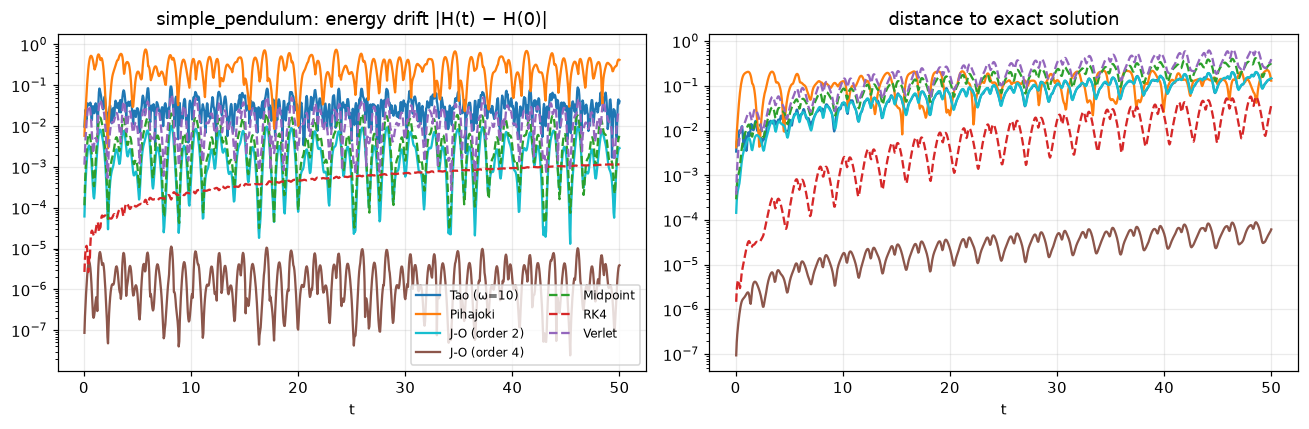

In [5]:
system = SYSTEM_BUILDERS[SYSTEM]()
D = system.state_dim
d = D // 2
Y0 = system.generate_initial_conditions(N_TEST, seed=SEED_TEST)
f_flat = oracle_field_batched(system, N_TEST, d)
H_true = true_H_fn(system)

# Energy drift + state error over time
ref_A = solve_reference(f_flat, Y0, d, A_T, A_STEPS, 1e-10, 1e-10)
RUN_A = run_all(METHODS_TRUE, Y0, d, A_T, A_STEPS, f_flat, system.dynamics)

t = np.linspace(0, A_T, A_STEPS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, r in RUN_A.items():
    if r["traj"] is None:
        continue
    curve(axes[0], t, energy_drift(H_true, r["traj"]), label)
    curve(axes[1], t, state_error(r["traj"], ref_A), label)
axes[0].set_title(f"{SYSTEM}: energy drift |H(t) − H(0)|")
axes[1].set_title("distance to exact solution")
for ax in axes:
    ax.set_xlabel("t")
axes[0].legend(ncol=2)
plt.tight_layout()
plt.show()

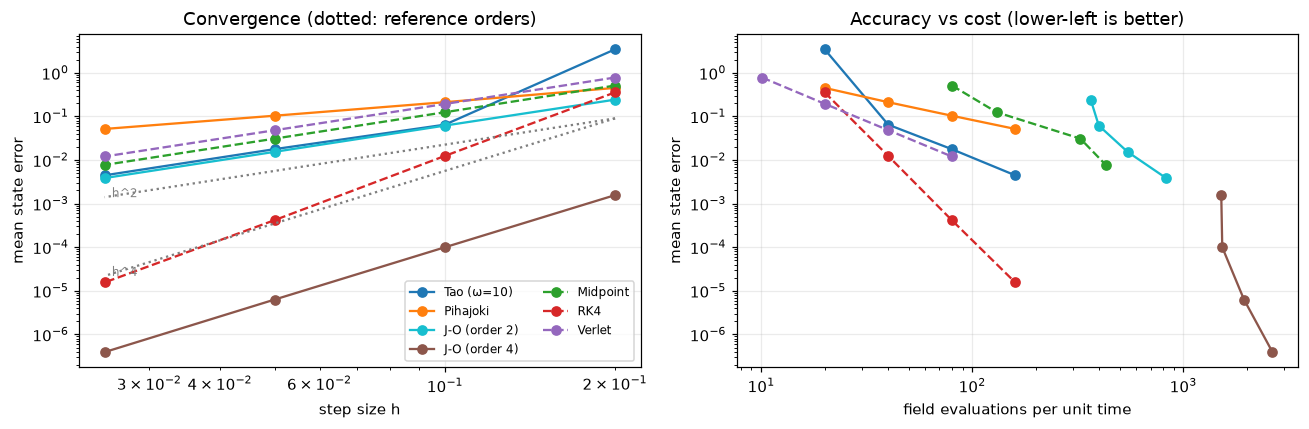

In [6]:
# Convergence order
SWEEP = {label: [] for label in METHODS_TRUE}
for n in CONV_STEPS:
    ref = solve_reference(f_flat, Y0, d, CONV_T, n, 1e-10, 1e-10)
    for label, r in run_all(
        METHODS_TRUE, Y0, d, CONV_T, n, f_flat, system.dynamics
    ).items():
        if r["traj"] is not None and np.isfinite(r["traj"]).all():
            h = CONV_T / n
            SWEEP[label].append((h, state_error(r["traj"], ref).mean(), r["evals"] / h))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, pts in SWEEP.items():
    if not pts:
        continue
    h, e, w = np.array(pts).T
    axes[0].loglog(
        h, e, "o-", label=label, **{k: v for k, v in sty(label).items() if k != "lw"}
    )
    axes[1].loglog(
        w, e, "o-", label=label, **{k: v for k, v in sty(label).items() if k != "lw"}
    )
hh = np.array([CONV_T / n for n in CONV_STEPS])
e0 = 0.2 * np.nanmedian([p[0][1] for p in SWEEP.values() if p])
for order in (2, 4):
    axes[0].loglog(hh, e0 * (hh / hh[0]) ** order, ":", color="gray")
    axes[0].text(
        hh[-1] * 1.03,
        e0 * (hh[-1] / hh[0]) ** order,
        f"h^{order}",
        color="gray",
        fontsize=8,
    )
axes[0].set_xlabel("step size h")
axes[0].set_ylabel("mean state error")
axes[0].set_title("Convergence (dotted: reference orders)")
axes[1].set_xlabel("field evaluations per unit time")
axes[1].set_ylabel("mean state error")
axes[1].set_title("Accuracy vs cost (lower-left is better)")
axes[0].legend(ncol=2)
plt.tight_layout()
plt.show()

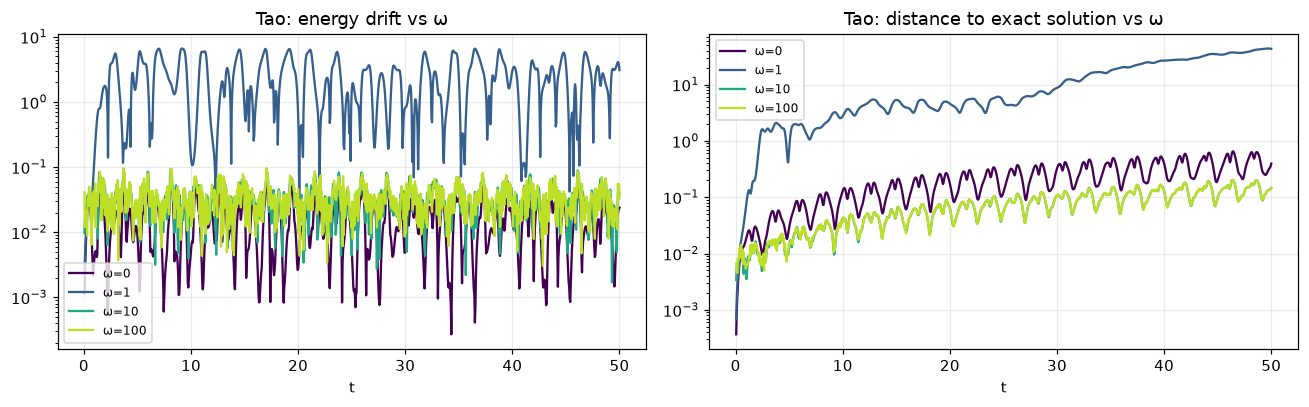

In [7]:
# Tao restraint ω
OM = {f"ω={w:g}": ("tao", w) for w in OMEGAS}
RUN_OM = run_all(OM, Y0, d, A_T, A_STEPS, f_flat, system.dynamics)
cmap = plt.cm.viridis(np.linspace(0, 0.9, len(OM)))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for c, (label, r) in zip(cmap, RUN_OM.items()):
    if r["traj"] is None:
        continue
    for ax, y in zip(
        axes, (energy_drift(H_true, r["traj"]), state_error(r["traj"], ref_A))
    ):
        ax.semilogy(t[1:], y[1:] + 1e-16, color=c, label=label)
axes[0].set_title("Tao: energy drift vs ω")
axes[1].set_title("Tao: distance to exact solution vs ω")
for ax in axes:
    ax.set_xlabel("t")
    ax.legend()
plt.tight_layout()
plt.show()

# Integrators on learned models

MLP            trained in   7.2s, final loss 1.01e+00
HNN            trained in   7.4s, final loss 1.06e+00
DoubleHeadHNN  trained in   7.8s, final loss 1.12e+00
CholeskyHNN    trained in  10.5s, final loss 1.11e+00
GeoHNN         trained in  24.2s, final loss 1.02e+00


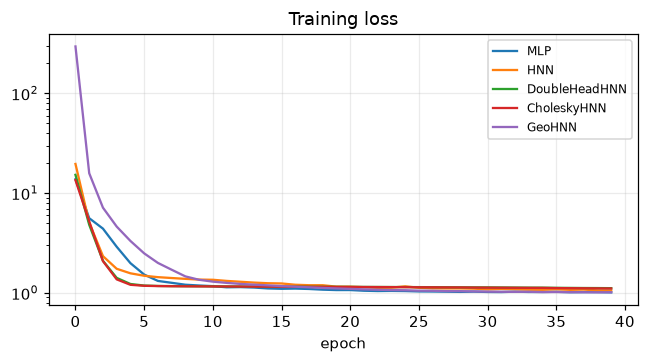

In [8]:
import torch
from src.models.baselines import MLP, HNN, DoubleHeadHNN, CholeskyHNN
from src.models.geohnn import GeoHNN
from src.models.api import predict_derivative
from src.integrators.model_field import batched_field, model_vector_field


def build_model(name, state_dim):
    d = state_dim // 2
    return {
        "MLP": lambda: MLP(state_dim, HIDDEN),
        "HNN": lambda: HNN(state_dim, HIDDEN),
        "DoubleHeadHNN": lambda: DoubleHeadHNN(state_dim, HIDDEN),
        "CholeskyHNN": lambda: CholeskyHNN(state_dim, HIDDEN),
        "GeoHNN": lambda: GeoHNN(d),
    }[name]()


def train_model(model, X, dX, epochs, batch, lr, seed=0):
    torch.manual_seed(seed)
    X = torch.as_tensor(X, dtype=torch.float32)
    dX = torch.as_tensor(dX, dtype=torch.float32)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n, hist = X.shape[0], []
    model.train()
    for ep in range(epochs):
        perm, tot = torch.randperm(n), 0.0
        for i in range(0, n, batch):
            idx = perm[i : i + batch]
            loss = ((predict_derivative(model, X[idx]) - dX[idx]) ** 2).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += loss.item() * len(idx)
        hist.append(tot / n)
    model.eval()
    return hist


def learned_hamiltonian(model, name):
    # H_learned(X) for (M, 2d) numpy states; None for the (non-Hamiltonian) MLP
    if name == "MLP":
        return None
    dtype = next(model.parameters()).dtype

    def H(X):
        x = torch.as_tensor(np.asarray(X), dtype=dtype)
        with torch.no_grad():
            if name == "GeoHNN":
                h = model.compute_hamiltonian(
                    x[:, : model.n_dof].contiguous(), x[:, model.n_dof :].contiguous()
                )[0]
            else:
                h = model(x)
        return h.reshape(-1).double().numpy()

    return H


data = generate_dataset(
    system, N_TRAIN, TSPAN_TRAIN, STEPS_TRAIN, seed=SEED_TRAIN, system_key=SYSTEM
)
X, dX = data["X"].reshape(-1, D), data["dX"].reshape(-1, D)

TRAINED, HISTORY = {}, {}
for name in MODELS:
    t0 = time.perf_counter()
    try:
        m = build_model(name, D)
        HISTORY[name] = train_model(m, X, dX, EPOCHS, BATCH, LR)
        TRAINED[name] = m
        print(
            f"{name:14s} trained in {time.perf_counter() - t0:5.1f}s, final loss {HISTORY[name][-1]:.2e}"
        )
    except Exception as e:
        print(f"{name:14s} FAILED: {type(e).__name__}: {e}")

fig, ax = plt.subplots(figsize=(6, 3.4))
for name, h in HISTORY.items():
    ax.semilogy(h, label=name)
ax.set_xlabel("epoch")
ax.set_title("Training loss")
ax.legend()
plt.tight_layout()
plt.show()

MLP            done
HNN            done
DoubleHeadHNN  done
CholeskyHNN    done
GeoHNN         done


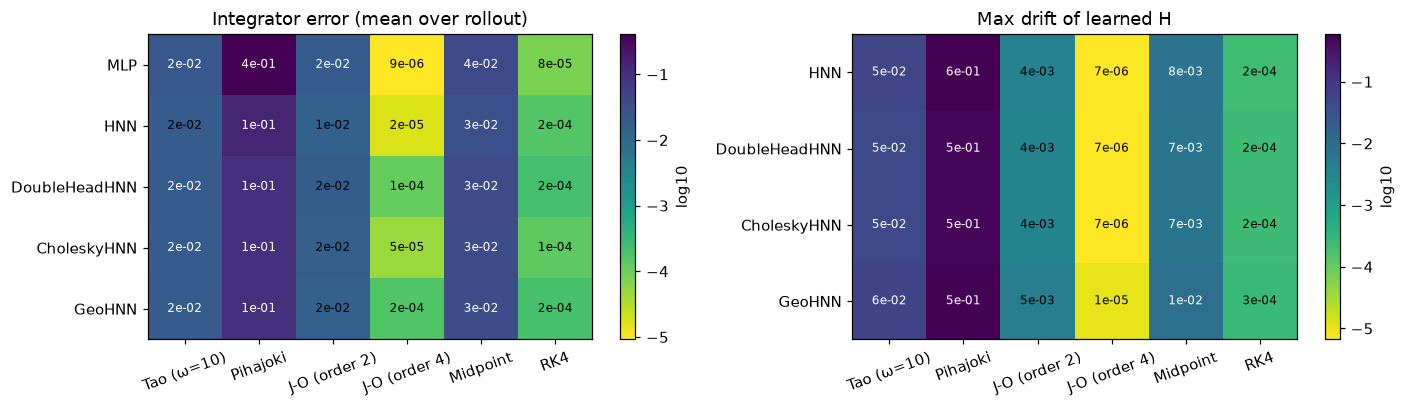

In [9]:
# Roll out every trained model with every integrator
RES, REF_MODEL, H_LEARNED = {}, {}, {}
for name, model in TRAINED.items():
    f_b, f_s = batched_field(model, N_TEST, d), model_vector_field(model)
    H_LEARNED[name] = learned_hamiltonian(model, name)
    try:
        REF_MODEL[name] = solve_reference(
            f_b, Y0, d, ROLL_T, ROLL_STEPS, REF_RTOL, REF_ATOL
        )
    except Exception as e:
        print(f"{name}: reference solve of the learned field failed ({e}); skipping")
        continue
    RES[name] = run_all(METHODS_LEARNED, Y0, d, ROLL_T, ROLL_STEPS, f_b, f_s)
    print(f"{name:14s} done")


def heatmap(ax, getter, title, models, methods):
    M = np.full((len(models), len(methods)), np.nan)
    for i, m in enumerate(models):
        for j, meth in enumerate(methods):
            v = getter(m, meth)
            M[i, j] = v if (v is not None and np.isfinite(v) and v > 0) else np.nan
    im = ax.imshow(np.log10(M), cmap="viridis_r", aspect="auto")
    ax.set_xticks(range(len(methods)), methods, rotation=20)
    ax.set_yticks(range(len(models)), models)
    for i in range(len(models)):
        for j in range(len(methods)):
            ax.text(
                j,
                i,
                "n/a" if np.isnan(M[i, j]) else f"{M[i, j]:.0e}",
                ha="center",
                va="center",
                fontsize=8,
                color=(
                    "white"
                    if (
                        not np.isnan(M[i, j])
                        and np.log10(M[i, j]) > np.nanmedian(np.log10(M))
                    )
                    else "black"
                ),
            )
    ax.set_title(title)
    ax.grid(False)
    plt.colorbar(im, ax=ax, label="log10")


def int_err(m, meth):
    r = RES[m][meth]
    return None if r["traj"] is None else state_error(r["traj"], REF_MODEL[m]).mean()


def max_Hdrift(m, meth):
    r = RES[m][meth]
    if r["traj"] is None or H_LEARNED[m] is None:
        return None
    return energy_drift(H_LEARNED[m], r["traj"]).max()


models_ok, methods = list(RES), list(METHODS_LEARNED)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
heatmap(axes[0], int_err, "Integrator error (mean over rollout)", models_ok, methods)
heatmap(
    axes[1],
    max_Hdrift,
    "Max drift of learned H",
    [m for m in models_ok if H_LEARNED[m] is not None],
    methods,
)
plt.tight_layout()
plt.show()

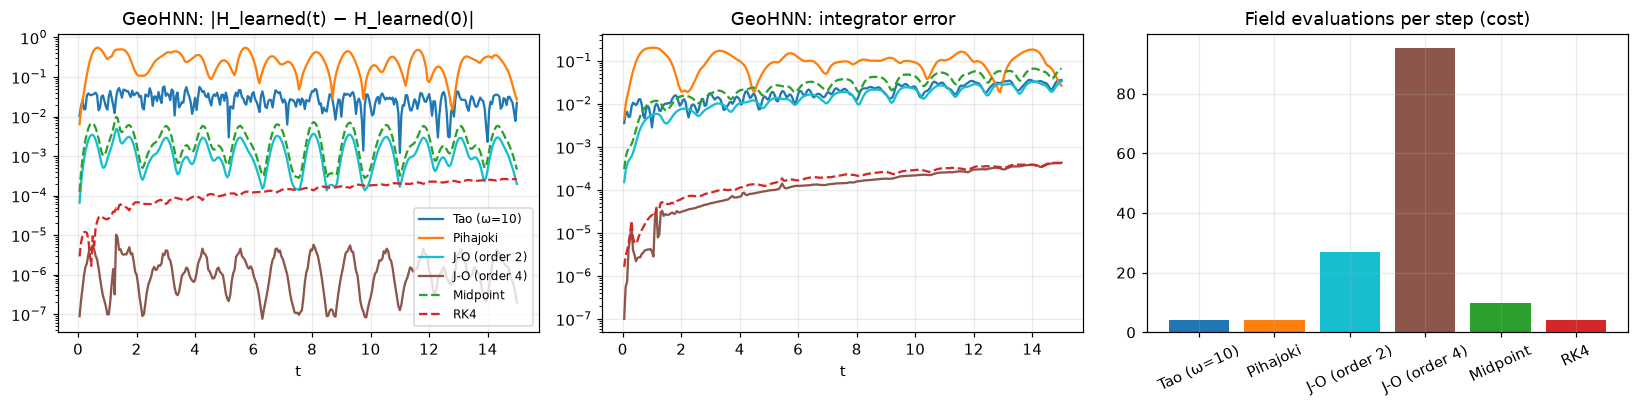

In [10]:
# Zoom on one model: errors over time + cost
focus = FOCUS_MODEL if FOCUS_MODEL in RES else models_ok[0]
tt = np.linspace(0, ROLL_T, ROLL_STEPS + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for label, r in RES[focus].items():
    if r["traj"] is None:
        continue
    curve(
        axes[0],
        tt,
        energy_drift(H_LEARNED[focus], r["traj"]) if H_LEARNED[focus] else None,
        label,
    )
    curve(axes[1], tt, state_error(r["traj"], REF_MODEL[focus]), label)
labels = [l for l, r in RES[focus].items() if r["traj"] is not None]
axes[2].bar(
    labels, [RES[focus][l]["evals"] for l in labels], color=[COLORS[l] for l in labels]
)
axes[2].set_title("Field evaluations per step (cost)")
axes[2].tick_params(axis="x", rotation=25)
axes[0].set_title(f"{focus}: |H_learned(t) − H_learned(0)|")
axes[1].set_title(f"{focus}: integrator error")
for ax in axes[:2]:
    ax.set_xlabel("t")
axes[0].legend()
plt.tight_layout()
plt.show()

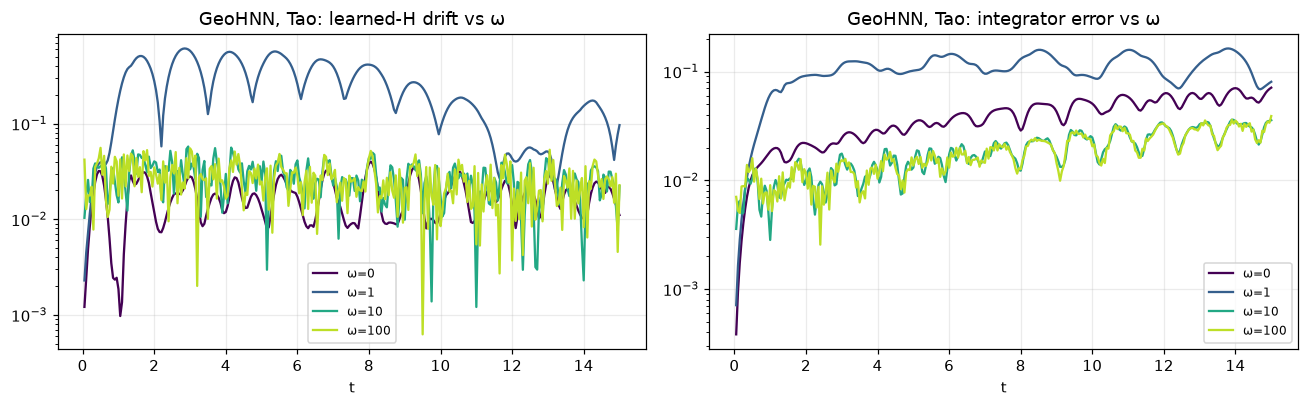

In [11]:
# Tao restraint ω on the focus model
f_b, f_s = batched_field(TRAINED[focus], N_TEST, d), model_vector_field(TRAINED[focus])
RUN_OM_M = run_all(
    {f"ω={w:g}": ("tao", w) for w in OMEGAS}, Y0, d, ROLL_T, ROLL_STEPS, f_b, f_s
)
cmap = plt.cm.viridis(np.linspace(0, 0.9, len(RUN_OM_M)))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for c, (label, r) in zip(cmap, RUN_OM_M.items()):
    if r["traj"] is None:
        continue
    if H_LEARNED[focus]:
        axes[0].semilogy(
            tt[1:],
            energy_drift(H_LEARNED[focus], r["traj"])[1:] + 1e-16,
            color=c,
            label=label,
        )
    axes[1].semilogy(
        tt[1:],
        state_error(r["traj"], REF_MODEL[focus])[1:] + 1e-16,
        color=c,
        label=label,
    )
axes[0].set_title(f"{focus}, Tao: learned-H drift vs ω")
axes[1].set_title(f"{focus}, Tao: integrator error vs ω")
for ax in axes:
    ax.set_xlabel("t")
    ax.legend()
plt.tight_layout()
plt.show()